<a href="https://colab.research.google.com/github/fernandyan/MyGoogleColab/blob/main/fernand_flask2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import tensorflow as tf

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, Normalizer, StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, max_error, mean_absolute_percentage_error, root_mean_squared_error

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier # rfC- 0.7412, gbc-0.721875, abc - 0.4834
from sklearn.neighbors import KNeighborsClassifier # 2 - 0.6112
from sklearn.tree import DecisionTreeClassifier # 2 - 0.64875
from sklearn.svm import SVC # 1 - 0.8175
from sklearn.naive_bayes import GaussianNB

from sklearn.linear_model import LinearRegression # 0.4909528790305868
from sklearn.ensemble import RandomForestRegressor # 0.854639819213566
from sklearn.tree import DecisionTreeRegressor # 0.7812665091285166
from sklearn.svm import SVR # 0.723410803475629

# fast food

In [ ]:
df = pd.read_csv("/content/fast_food_cheat_meal_workout_burn.csv")

In [ ]:
df.head(3)

,order_id,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,...,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct,workout_shock_tier
0,FFC-00001,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,...,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7,High Sweat Penalty
1,FFC-00002,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,...,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4,Extreme / Half-Marathon Toll
2,FFC-00003,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,...,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0,Extreme / Half-Marathon Toll


In [ ]:
df.columns

Index(['order_id', 'fast_food_chain', 'meal_category', 'item_count',
       'total_calories', 'fat_grams', 'saturated_fat_grams', 'carb_grams',
       'sugar_grams', 'protein_grams', 'sodium_mg', 'consumer_gender',
       'consumer_age', 'consumer_weight_kg', 'fitness_level',
       'thermic_effect_calories', 'net_caloric_surplus',
       'walking_burn_time_min', 'cycling_burn_time_min',
       'running_burn_time_min', 'hiit_burn_time_min',
       'daily_calorie_allowance_pct', 'workout_shock_tier'],
      dtype='object')

In [ ]:
df['total_calories'].unique()

array([1015, 1849, 1920, ..., 2408, 2818, 2891])

In [ ]:
df.isnull().sum()

,0
order_id,0
fast_food_chain,0
meal_category,0
item_count,0
total_calories,0
fat_grams,0
saturated_fat_grams,0
carb_grams,0
sugar_grams,0
protein_grams,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   order_id                     8000 non-null   object 
 1   fast_food_chain              8000 non-null   object 
 2   meal_category                8000 non-null   object 
 3   item_count                   8000 non-null   int64  
 4   total_calories               8000 non-null   int64  
 5   fat_grams                    8000 non-null   int64  
 6   saturated_fat_grams          8000 non-null   int64  
 7   carb_grams                   8000 non-null   int64  
 8   sugar_grams                  8000 non-null   int64  
 9   protein_grams                8000 non-null   int64  
 10  sodium_mg                    8000 non-null   int64  
 11  consumer_gender              8000 non-null   object 
 12  consumer_age                 8000 non-null   int64  
 13  consumer_weight_kg

In [ ]:
X = df.drop(columns=['workout_shock_tier','order_id'])
y = df['workout_shock_tier']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X.head()

,fast_food_chain,meal_category,item_count,total_calories,fat_grams,saturated_fat_grams,carb_grams,sugar_grams,protein_grams,sodium_mg,...,consumer_age,consumer_weight_kg,fitness_level,thermic_effect_calories,net_caloric_surplus,walking_burn_time_min,cycling_burn_time_min,running_burn_time_min,hiit_burn_time_min,daily_calorie_allowance_pct
0,McDonald's,Late-Night Value Menu Binge,3,1015,47,19,117,55,32,1632,...,61,96.0,Moderately Active,77.9,937.1,168.3,80.8,60.2,46.5,50.7
1,Taco Bell,Fried Chicken Bucket & Slaw,5,1849,103,32,166,61,65,2806,...,65,53.6,Moderately Active,136.7,1712.3,550.7,261.7,185.5,161.1,92.4
2,Domino's Pizza,Pizza Feast & Cheesy Bread,2,1920,106,50,184,61,57,2122,...,35,67.0,Moderately Active,135.0,1785.0,463.9,219.5,157.8,131.1,96.0
3,McDonald's,Dessert Overload & Large Shake,2,1255,67,25,135,42,27,1883,...,61,62.6,Sedentary,82.3,1172.7,351.0,166.5,120.3,103.4,62.7
4,Taco Bell,Double Burger & Large Fry,4,1665,88,32,155,69,62,2305,...,19,73.0,Moderately Active,127.4,1537.6,361.3,170.9,119.1,104.9,83.2


## pipeline e columntransformer

In [ ]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(include="object").columns

In [ ]:
# 1. Definir os transformadores para cada tipo de coluna
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
    # ('scaler', MinMaxScaler())
    # ('scaler', Normalizer())
])

In [ ]:
# 1. Definir os transformadores para cada tipo de coluna
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='error')),
    # ('scaler', MinMaxScaler())
    ('scaler', StandardScaler())
    # ('scaler', Normalizer())
])

In [ ]:
# 2. Criar o ColumnTransformer para processar as colunas em paralelo
preprocessor = ColumnTransformer(
    transformers=[
        # ('num', num_transformer, ['idade', 'salario']),
        ('n', num_transformer, num_cols),
        # ('cat', cat_transformer, ['cidade', 'genero'])
        ('c', cat_transformer, cat_cols)
    ],
    remainder='passthrough' # Mantém colunas não listadas (opcional)
)

In [ ]:
# 3. Criar o Pipeline final que inclui o pré-processamento e o modelo
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    # ('classifier', SVC())
    ('classifier', RandomForestClassifier())
])

In [ ]:
# transform in pandas
preprocessor.set_output(transform="pandas")

ColumnTransformer(remainder='passthrough',
                  transformers=[('n',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams',
       'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg',
       'consumer_age', 'consumer_weight_kg', 'thermic_effect_calories',
       'net_calor...e_min', 'cycling_burn_time_min',
       'running_burn_time_min', 'hiit_burn_time_min',
       'daily_calorie_allowance_pct'],
      dtype='object')),
                                ('c',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder', OrdinalEncoder()),
                                                 ('scaler', StandardScaler())]),
                                 Index(['fast_food_chain', 'meal_category', 'consumer_gender', 'fitness_level'], dtype='object'))])

In [ ]:
df_pre = preprocessor.fit_transform(X)
df_pre

,n__item_count,n__total_calories,n__fat_grams,n__saturated_fat_grams,n__carb_grams,n__sugar_grams,n__protein_grams,n__sodium_mg,n__consumer_age,n__consumer_weight_kg,...,n__net_caloric_surplus,n__walking_burn_time_min,n__cycling_burn_time_min,n__running_burn_time_min,n__hiit_burn_time_min,n__daily_calorie_allowance_pct,c__fast_food_chain,c__meal_category,c__consumer_gender,c__fitness_level
0,-0.448756,-0.874255,-0.964268,-0.901709,-0.691682,-0.228061,-0.718097,-0.715488,1.400937,1.306343,...,-0.873389,-1.105779,-1.086452,-1.040177,-1.142217,-0.875734,0.007449,0.279588,0.929714,-0.422759
1,1.338672,0.366658,0.669028,0.001033,0.000546,-0.039340,0.357228,0.378899,1.688049,-1.737773,...,0.371377,1.219459,1.246542,1.217962,1.282405,0.365172,1.111010,-0.308709,-1.075600,-0.422759
2,-1.342470,0.472299,0.756526,1.250984,0.254834,-0.039340,0.096543,-0.258716,-0.465292,-0.775718,...,0.488114,0.691659,0.702306,0.718756,0.647687,0.472301,-1.096112,1.456184,-1.075600,-0.422759
3,-1.342470,-0.517158,-0.380948,-0.485059,-0.437395,-0.636955,-0.881024,-0.481509,1.400937,-1.091616,...,-0.495078,0.005155,0.018787,0.042936,0.061631,-0.518638,0.007449,-1.485304,-1.075600,0.974792
4,0.444958,0.092883,0.231538,0.001033,-0.154852,0.212287,0.259471,-0.088126,-1.613740,-0.344946,...,0.090855,0.067785,0.075532,0.021310,0.093367,0.091399,1.111010,-0.897007,0.929714,-0.422759
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,-1.342470,0.237210,0.114874,-0.207292,0.057054,0.463914,0.911182,0.596099,-1.541962,-0.409562,...,0.207913,0.042247,0.044580,-0.014734,0.008738,0.237213,-1.463966,-0.308709,0.929714,-1.820310
7996,-0.448756,1.808437,2.098162,1.737075,2.260882,0.809901,-0.555169,1.806077,-1.183072,1.981218,...,1.875951,0.748209,0.779686,0.731372,0.668844,1.808432,0.743156,-0.308709,0.929714,0.974792
7997,1.338672,-0.539476,-0.497612,-0.346176,-0.564538,-0.448234,-0.359655,-0.598032,1.042046,2.663273,...,-0.539075,-0.956803,-1.078714,-0.915827,-1.013157,-0.539469,1.478864,1.456184,0.929714,0.974792
7998,0.444958,0.330948,-0.060122,-0.346176,0.184198,0.778448,1.562894,0.503812,0.467822,-1.831107,...,0.274069,1.195137,1.213011,1.122446,1.098337,0.329463,-0.360405,-0.308709,-1.075600,-0.422759


<Axes: >

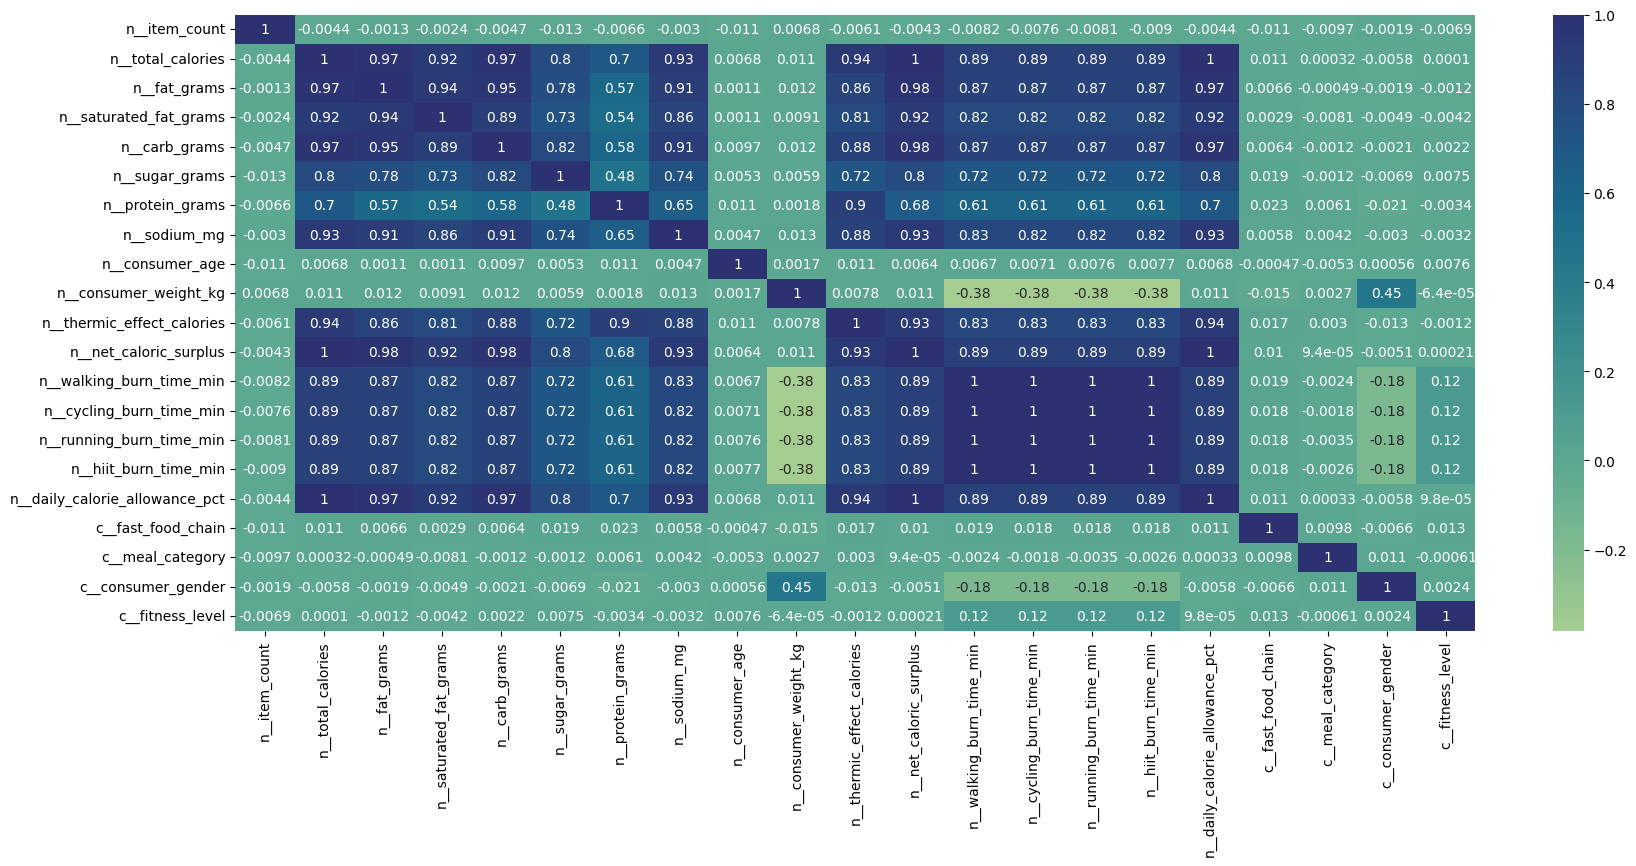

In [ ]:
plt.figure(figsize=(20, 8))
sns.heatmap(df_pre.corr(), annot=True, cmap="crest")

In [ ]:
clf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('n',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['item_count', 'total_calories', 'fat_grams', 'saturated_fat_grams',
       'carb_grams', 'sugar_grams', 'protein_grams', 'sodium_mg',
       'consumer_age', 'consumer_weight_kg', 'the...
       'running_burn_time_min', 'hiit_burn_time_min',
       'daily_calorie_allowance_pct'],
      dtype='object')),
                                                 ('c',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['fast_food_chain', 'meal_category', 'consumer_gender', 'fitness_level'], dtype='object'))])),
                ('classifier', RandomForestClassifier())])

In [ ]:
clf.score(X_test, y_test)

0.999375

## cross val data

In [ ]:
df_pre.head()

,n__item_count,n__total_calories,n__fat_grams,n__saturated_fat_grams,n__carb_grams,n__sugar_grams,n__protein_grams,n__sodium_mg,n__consumer_age,n__consumer_weight_kg,...,n__net_caloric_surplus,n__walking_burn_time_min,n__cycling_burn_time_min,n__running_burn_time_min,n__hiit_burn_time_min,n__daily_calorie_allowance_pct,c__fast_food_chain,c__meal_category,c__consumer_gender,c__fitness_level
0,-0.448756,-0.874255,-0.964268,-0.901709,-0.691682,-0.228061,-0.718097,-0.715488,1.400937,1.306343,...,-0.873389,-1.105779,-1.086452,-1.040177,-1.142217,-0.875734,0.007449,0.279588,0.929714,-0.422759
1,1.338672,0.366658,0.669028,0.001033,0.000546,-0.039340,0.357228,0.378899,1.688049,-1.737773,...,0.371377,1.219459,1.246542,1.217962,1.282405,0.365172,1.111010,-0.308709,-1.075600,-0.422759
2,-1.342470,0.472299,0.756526,1.250984,0.254834,-0.039340,0.096543,-0.258716,-0.465292,-0.775718,...,0.488114,0.691659,0.702306,0.718756,0.647687,0.472301,-1.096112,1.456184,-1.075600,-0.422759
3,-1.342470,-0.517158,-0.380948,-0.485059,-0.437395,-0.636955,-0.881024,-0.481509,1.400937,-1.091616,...,-0.495078,0.005155,0.018787,0.042936,0.061631,-0.518638,0.007449,-1.485304,-1.075600,0.974792
4,0.444958,0.092883,0.231538,0.001033,-0.154852,0.212287,0.259471,-0.088126,-1.613740,-0.344946,...,0.090855,0.067785,0.075532,0.021310,0.093367,0.091399,1.111010,-0.897007,0.929714,-0.422759


In [ ]:
cross_val_data = cross_val_score(clf, X, y, cv=5, scoring="accuracy")


In [ ]:
cross_val_data

array([1.      , 1.      , 0.999375, 1.      , 1.      ])

In [ ]:
cross_val_data.mean()

np.float64(0.9998750000000001)

## my sns and pipeline other

In [ ]:
#sns.pairplot(X.sample(100))

<Axes: >

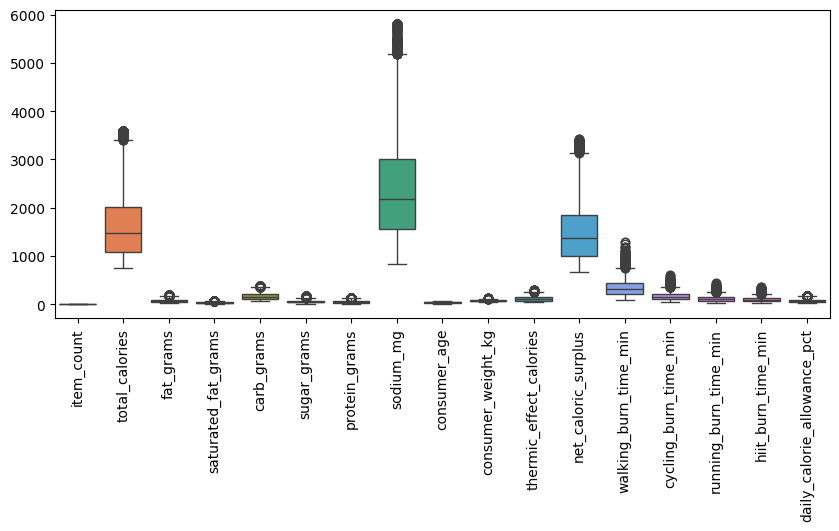

In [ ]:
plt.figure(figsize=(10, 4))
plt.xticks(rotation='vertical')  # ou rotation=90
sns.boxplot(X)

In [ ]:
#sns.heatmap(X.corr(), annot=True, cmap="crest")

In [ ]:
pipeline_mode = Pipeline([
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
    ('normalizer', Normalizer()),
    ('simpleImputer', SimpleImputer()),
    ('classifier', SVC()),
])
pipeline_mode

Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
                ('normalizer', Normalizer()),
                ('simpleImputer', SimpleImputer()), ('classifier', SVC())])

In [ ]:
pipeline_mode.fit(X_train, y_train)

Pipeline(steps=[('one_hot_encoder', OneHotEncoder(handle_unknown='ignore')),
                ('normalizer', Normalizer()),
                ('simpleImputer', SimpleImputer()), ('classifier', SVC())])

In [ ]:
pipeline_mode.score(X_test, y_test)

0.8175

## value_count

In [ ]:
y.unique()

array(['High Sweat Penalty', 'Extreme / Half-Marathon Toll',
       'Severe Cardio Deficit', 'Moderate Burn'], dtype=object)

In [ ]:
y.value_counts()

,count
workout_shock_tier,
Extreme / Half-Marathon Toll,3257
Severe Cardio Deficit,2429
High Sweat Penalty,2122
Moderate Burn,192


In [ ]:
y.value_counts(normalize=True)

,proportion
workout_shock_tier,
Extreme / Half-Marathon Toll,0.407125
Severe Cardio Deficit,0.303625
High Sweat Penalty,0.265250
Moderate Burn,0.024000


# new exam performance

In [105]:
df = pd.read_csv("/content/student_exam_performance.csv")

In [106]:
df.head()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low


In [107]:
X = df.drop(columns=['student_id'])
y = df['performance_level']

In [108]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [109]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(include="object").columns

## preprocessing

In [110]:
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [111]:
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='error')),
    ('scaler', StandardScaler())
])

In [112]:
CT_preprocessor = ColumnTransformer(
    transformers=[
        ('n', num_transformer, num_cols),
        ('c', cat_transformer, cat_cols)
    ],
    remainder='passthrough'
)

In [113]:
clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier())
])

In [114]:
CT_preprocessor.set_output(transform="pandas")

ColumnTransformer(remainder='passthrough',
                  transformers=[('n',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours',
       'private_tuition', 'online_learning_hours', 'practice_te...
                                 Index(['gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty', 'performance_grade',
       'pass_status', 'performance_level'],
      dtype='object'))])

In [115]:
X_pre = CT_preprocessor.fit_transform(X)
X_pre

,n__age,n__previous_exam_score,n__previous_gpa,n__attendance_percentage,n__assignment_completion_rate,n__study_hours_per_day,n__self_study_hours,n__private_tuition,n__online_learning_hours,n__practice_tests_completed,...,c__notes_quality,c__sleep_quality,c__break_frequency,c__motivation_level,c__device_availability,c__educational_app_usage,c__exam_difficulty,c__performance_grade,c__pass_status,c__performance_level
0,1.497466,0.775897,0.368415,-0.417460,-0.374731,1.130750,0.422595,-0.654342,-0.127019,0.995886,...,-0.700992,-1.623720,-1.281146,-1.369586,1.724097,-0.270220,0.900307,-2.116111,0.540531,-1.895629
1,-0.002871,0.340008,0.237754,0.015952,0.561188,0.246750,0.430493,-0.654342,-0.017332,1.795528,...,-0.700992,-1.623720,-1.281146,-1.369586,1.724097,1.066643,-1.515975,-2.116111,0.540531,-1.895629
2,0.497241,1.162572,1.239489,2.043417,0.054885,-1.125777,-0.999140,-0.654342,0.695633,-0.203577,...,0.577024,1.704667,1.573521,0.921649,-0.580014,-0.270220,-1.515975,-1.275984,0.540531,1.040577
3,1.497466,-0.783987,-0.459105,0.037224,0.439972,2.846407,2.697370,-0.654342,-0.032290,0.995886,...,0.577024,-0.514258,1.573521,-1.369586,-0.580014,-0.270220,0.900307,-1.275984,0.540531,1.040577
4,-0.502983,0.462162,0.128870,0.475954,-0.674885,-0.212698,0.154045,-0.654342,-0.710354,-1.802861,...,1.855041,-1.623720,-1.281146,-1.369586,-0.580014,1.066643,0.900307,0.404269,0.540531,-0.427526
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,-0.002871,0.808412,-0.001791,0.670059,-0.721887,-1.067619,-1.117617,-0.654342,-0.221749,0.596065,...,-0.700992,-0.514258,0.146188,0.921649,1.724097,-1.607083,0.900307,-0.435858,0.540531,1.040577
99996,-1.503207,0.542134,0.433746,-0.101042,2.033096,3.253513,3.582005,-0.654342,-0.755226,2.595170,...,-0.700992,-1.623720,-1.281146,-0.223968,-0.580014,-0.270220,-1.515975,-2.116111,0.540531,-1.895629
99997,-0.502983,1.332182,1.065274,0.656764,0.128274,-0.317382,0.082958,-0.654342,1.159309,-0.203577,...,-0.700992,-0.514258,0.146188,0.921649,-0.580014,1.066643,0.900307,-0.435858,0.540531,1.040577
99998,-1.003095,0.454253,0.607960,1.060927,-0.038295,1.031881,1.441505,1.528253,-0.795112,0.596065,...,-0.700992,1.704667,1.573521,0.921649,1.724097,1.066643,0.900307,-2.116111,0.540531,-1.895629


## plt

In [116]:
# plt.figure(figsize=(30, 16))
# sns.heatmap(X_pre.corr(), annot=True, cmap="crest")

<Axes: >

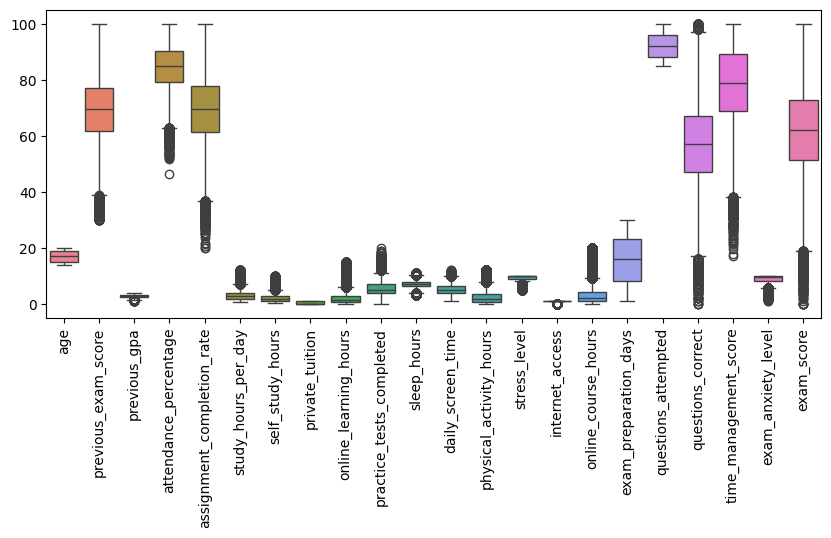

In [117]:
plt.figure(figsize=(10, 4))
plt.xticks(rotation='vertical')  # ou rotation=90
sns.boxplot(X)

## fit

In [118]:
clf.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('n',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['age', 'previous_exam_score', 'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'study_hours_per_day', 'self_study_hours',
       'private_tuition', 'onl...
       'parent_education', 'urban_rural', 'class_participation',
       'study_consistency', 'study_environment', 'study_method',
       'revision_frequency', 'notes_quality', 'sleep_quality',
       'break_frequency', 'motivation_level', 'device_availability',
       'educational_app_usage', 'exam_difficulty', 'performance_grade',
       'pass_status', 'performance_level'],
      dtype='object'))])),
                ('classifier', RandomForestClassifier())])

In [119]:
clf.score(X_test, y_test)

1.0

In [125]:
clf.classes_

array(['High', 'Low', 'Medium'], dtype=object)

In [128]:
clf.n_features_in_

43

In [129]:
clf.feature_names_in_

array(['age', 'gender', 'education_level', 'school_type', 'family_income',
       'parent_education', 'urban_rural', 'previous_exam_score',
       'previous_gpa', 'attendance_percentage',
       'assignment_completion_rate', 'class_participation',
       'study_hours_per_day', 'self_study_hours', 'private_tuition',
       'online_learning_hours', 'study_consistency', 'study_environment',
       'study_method', 'revision_frequency', 'practice_tests_completed',
       'notes_quality', 'sleep_hours', 'sleep_quality',
       'daily_screen_time', 'physical_activity_hours', 'break_frequency',
       'stress_level', 'motivation_level', 'internet_access',
       'device_availability', 'educational_app_usage',
       'online_course_hours', 'exam_difficulty', 'exam_preparation_days',
       'questions_attempted', 'questions_correct',
       'time_management_score', 'exam_anxiety_level', 'exam_score',
       'performance_grade', 'pass_status', 'performance_level'],
      dtype=object)

In [130]:
y.value_counts()

,count
performance_level,
Low,45123
Medium,41999
High,12878


In [131]:
y.value_counts(normalize=True)

,proportion
performance_level,
Low,0.45123
Medium,0.41999
High,0.12878
